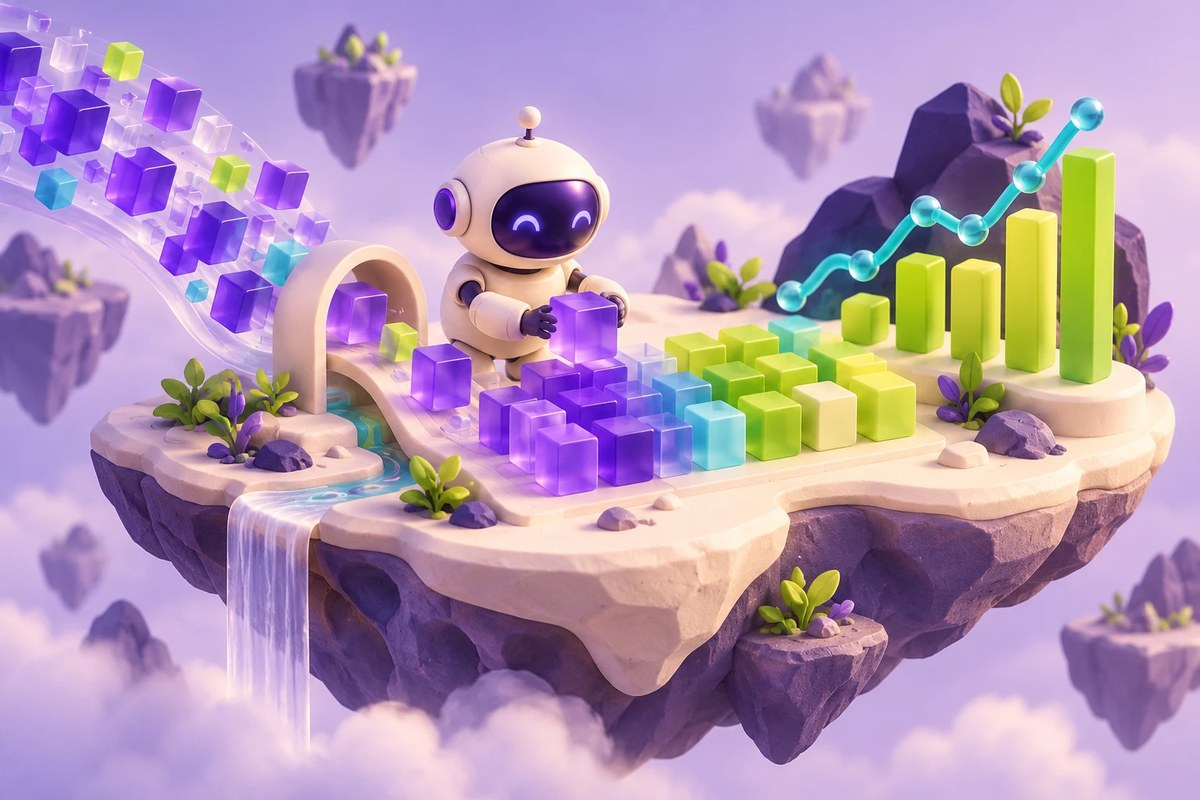

AI PATH · Python для машинного обучения · Урок 016

# Linux в Colab: расширенный файловый практикум

Размеры файлов, два CSV, ZIP/RAR/tar и справка APT

**Архивный учебный материал.** Код и сохранённые результаты относятся к исходному ноутбуку. Оформление не означает новый запуск или подтверждение старых метрик. Перед выполнением проверьте зависимости и ограничения.

<a id="ai-016-goal"></a>
## Что вы разберёте

Научиться проверять содержимое, размер и структуру данных и замечать неточности в текстовых подсказках.

### Перед началом

- Базовые ls, pwd, head
- Относительные и абсолютные пути
- Файл, архив и пакет

### Что понадобится

- Linux/Colab с IPython и каталогом sample_data
- wget, unzip, tar, git и pip для соответствующих разделов
- Сетевой доступ к двум NYC taxi CSV, LFW и архивной модели TensorFlow
- Отдельная учебная среда с правами apt для libarchive-dev

## Навигация по уроку

- [Цель и подготовка](#ai-016-goal)
- [Карта урока](#ai-016-map)
- [Открыть базовые файлы](#ai-016-section-01)
- [Различить строки и байты](#ai-016-section-02)
- [Разобрать пути и рабочую папку](#ai-016-section-03)
- [Проверить два скачанных CSV](#ai-016-section-04)
- [Различить форматы архивов](#ai-016-section-05)
- [Разделить Python-пакеты и APT](#ai-016-section-06)
- [Получить исходники через Git](#ai-016-section-07)
- [Сверить среду и дальнейший маршрут](#ai-016-section-08)
- [Проверьте понимание](#ai-016-practice)
- [Источники и ограничения](#ai-016-provenance)

<a id="ai-016-map"></a>
## Карта урока

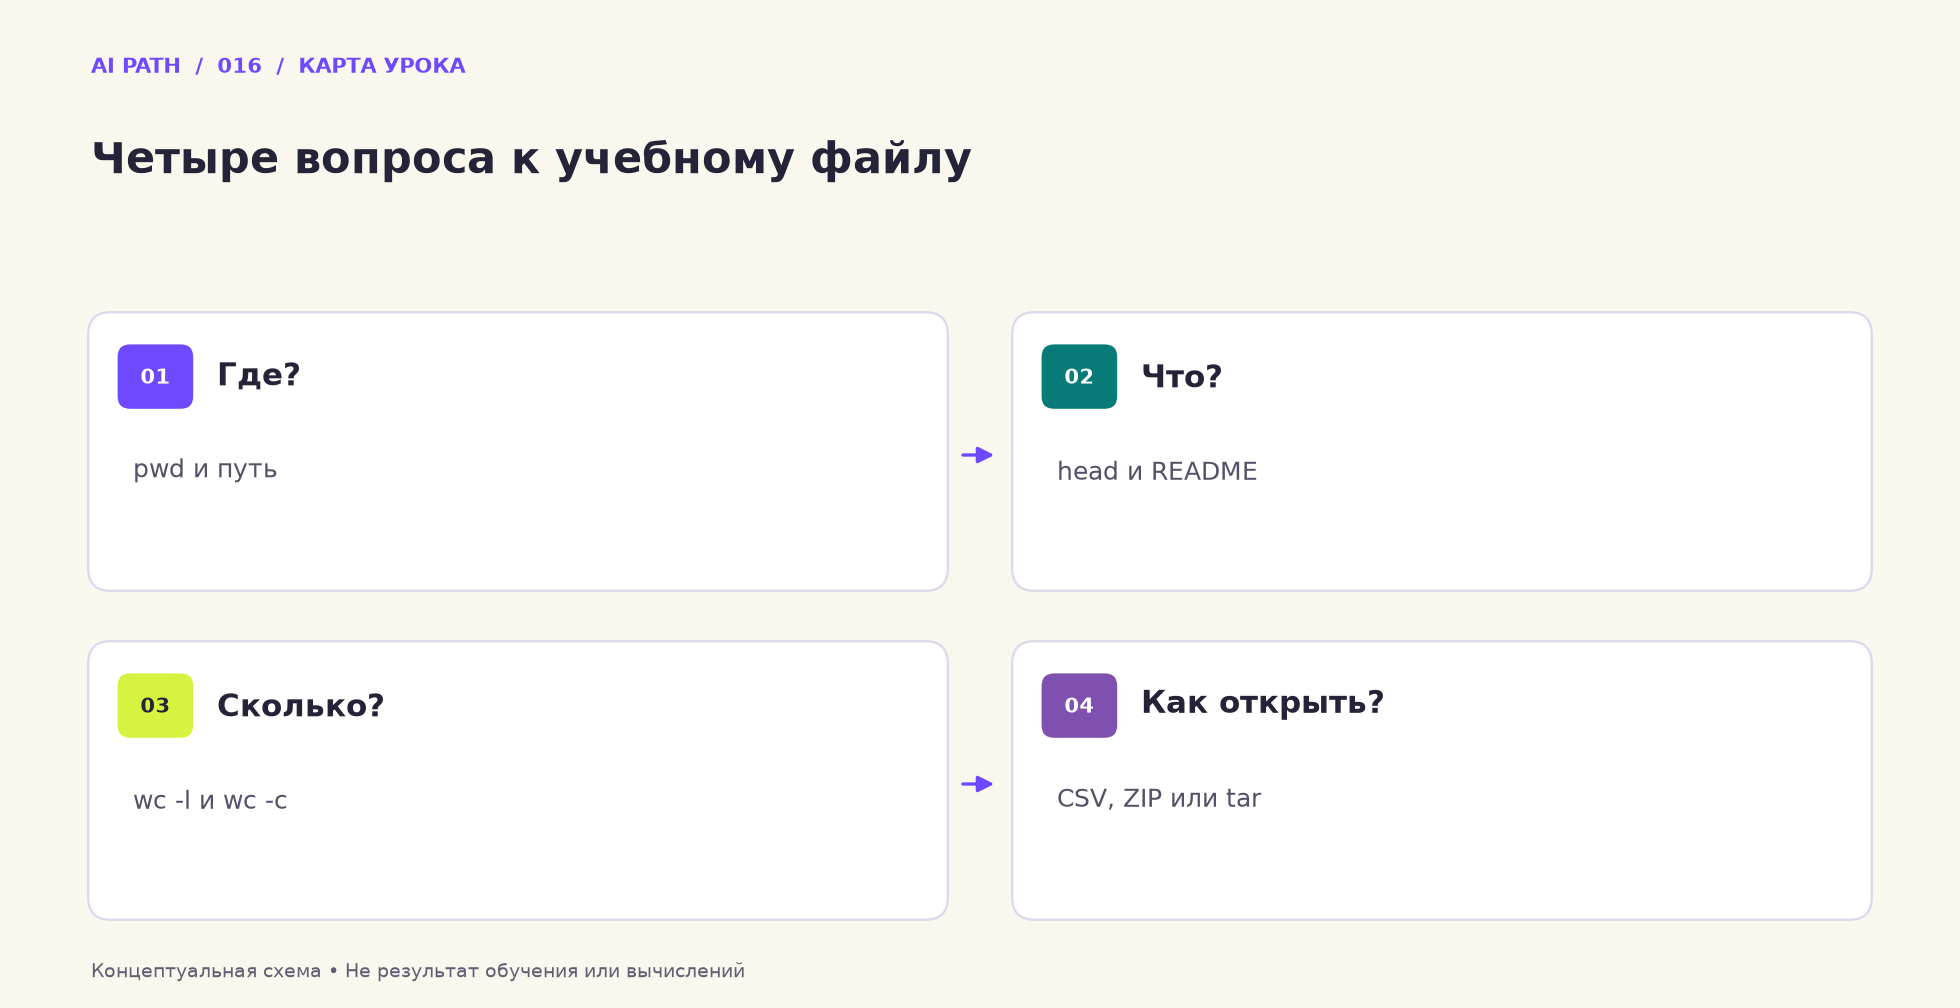

Схема показывает последовательность идей. Она не содержит результатов нового обучения или вычислений.

1. **Где?** — pwd и путь
2. **Что?** — head и README
3. **Сколько?** — wc -l и wc -c
4. **Как открыть?** — CSV, ZIP или tar

<a href="https://colab.research.google.com/github/safal207/hello-world/blob/master/%D0%A0%D0%B0%D0%B1%D0%BE%D1%82%D0%B0_%D1%81_Linux_%D0%BA%D0%BE%D0%BC%D0%B0%D0%BD%D0%B4%D0%B0%D0%BC%D0%B8_%D0%B2_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Команды Linux на платформе Google Colaboratory

Код ноутбуков, которые мы создаем на платформе Google Colaboratory, запускается на виртуальной машине в Linux в облаке Google. Для большинства задач в Colaboratory достаточно средств Python, но иногда все-таки приходится использовать команды операционной системы. Например, для загрузки данных или установки пакетов Python. Если вы привыкли работать с Windows, то использование команд Linux на первом этапе может вызвать затруднение.

В этом ноутбуке показаны примеры использования команд операционной системы Linux для выполнения часто встречающихся задач анализа данных на платформе Google Colaboratory

Чтобы запускать и редактировать код, сохраните копию этого ноутбука себе (File->Save a copy in Drive...). Свою копию вы сможете изменять и запускать.





<a id="ai-016-section-01"></a>
## 01 · Открыть базовые файлы

Начните с ls и head для train/test California Housing. Сверьте реальное число показанных строк с параметром команды.

_Далее — исходные ячейки учебного материала._

## Основы использования командной строки в Colab

Комады Linux в ноутбуках Colaboratory должны начинаться с восклицательного знака (!). Именно по наличию восклицательного знака в начале строки определяется, что это не код Python, а команда операционной системы. 

Пример:

In [ ]:

!ls

sample_data


`ls` - команда для получения списка файлов в каталоге. Мы можем видеть, что в текущем каталоге есть всего один файл - `sample_data`. 

Но это на самом деле не файл, а каталог. Давайте посмотрим, что находится в нем.

In [ ]:
!ls sample_data/

anscombe.json		      mnist_test.csv
california_housing_test.csv   mnist_train_small.csv
california_housing_train.csv  README.md


Если команде `ls` в качестве параметра указать имя каталога, то будет выведен список файлов в этом каталоге.

Каталог `sample_data`, как можно понять из названия, содержит демонстрационные данные. Этот каталог и данные в нем создаются автоматически при запуске виртуальной машины.

## Просмотр файлов

Как узнать, что находится в файлах с демонстрационными данными? Можно написать код на Python, но быстрее использовать команды Linux. Команда `head` выводит первые строки указанного ей файла. 

In [ ]:
!head sample_data/california_housing_test.csv


"longitude","latitude","housing_median_age","total_rooms","total_bedrooms","population","households","median_income","median_house_value"
-122.050000,37.370000,27.000000,3885.000000,661.000000,1537.000000,606.000000,6.608500,344700.000000
-118.300000,34.260000,43.000000,1510.000000,310.000000,809.000000,277.000000,3.599000,176500.000000
-117.810000,33.780000,27.000000,3589.000000,507.000000,1484.000000,495.000000,5.793400,270500.000000
-118.360000,33.820000,28.000000,67.000000,15.000000,49.000000,11.000000,6.135900,330000.000000
-119.670000,36.330000,19.000000,1241.000000,244.000000,850.000000,237.000000,2.937500,81700.000000
-119.560000,36.510000,37.000000,1018.000000,213.000000,663.000000,204.000000,1.663500,67000.000000
-121.430000,38.630000,43.000000,1009.000000,225.000000,604.000000,218.000000,1.664100,67000.000000
-120.650000,35.480000,19.000000,2310.000000,471.000000,1341.000000,441.000000,3.225000,166900.000000
-122.840000,38.400000,15.000000,3080.000000,617.000000,1446.000000,

In [ ]:
!head sample_data/california_housing_train.csv


"longitude","latitude","housing_median_age","total_rooms","total_bedrooms","population","households","median_income","median_house_value"
-114.310000,34.190000,15.000000,5612.000000,1283.000000,1015.000000,472.000000,1.493600,66900.000000
-114.470000,34.400000,19.000000,7650.000000,1901.000000,1129.000000,463.000000,1.820000,80100.000000
-114.560000,33.690000,17.000000,720.000000,174.000000,333.000000,117.000000,1.650900,85700.000000
-114.570000,33.640000,14.000000,1501.000000,337.000000,515.000000,226.000000,3.191700,73400.000000
-114.570000,33.570000,20.000000,1454.000000,326.000000,624.000000,262.000000,1.925000,65500.000000
-114.580000,33.630000,29.000000,1387.000000,236.000000,671.000000,239.000000,3.343800,74000.000000
-114.580000,33.610000,25.000000,2907.000000,680.000000,1841.000000,633.000000,2.676800,82400.000000
-114.590000,34.830000,41.000000,812.000000,168.000000,375.000000,158.000000,1.708300,48500.000000
-114.590000,33.610000,34.000000,4789.000000,1175.000000,3134.000000

В первой строке файла файла `california_housing_train.csv` заголовок, а в остальных данные, разделенные запятыми.

По-умолчанию команда head выводит 10 строк из файла. Можно показать любое количество срок, использую параметр `-n`. Давайте выведем 15 строк:

In [ ]:
!head -n 18 sample_data/california_housing_train.csv


"longitude","latitude","housing_median_age","total_rooms","total_bedrooms","population","households","median_income","median_house_value"
-114.310000,34.190000,15.000000,5612.000000,1283.000000,1015.000000,472.000000,1.493600,66900.000000
-114.470000,34.400000,19.000000,7650.000000,1901.000000,1129.000000,463.000000,1.820000,80100.000000
-114.560000,33.690000,17.000000,720.000000,174.000000,333.000000,117.000000,1.650900,85700.000000
-114.570000,33.640000,14.000000,1501.000000,337.000000,515.000000,226.000000,3.191700,73400.000000
-114.570000,33.570000,20.000000,1454.000000,326.000000,624.000000,262.000000,1.925000,65500.000000
-114.580000,33.630000,29.000000,1387.000000,236.000000,671.000000,239.000000,3.343800,74000.000000
-114.580000,33.610000,25.000000,2907.000000,680.000000,1841.000000,633.000000,2.676800,82400.000000
-114.590000,34.830000,41.000000,812.000000,168.000000,375.000000,158.000000,1.708300,48500.000000
-114.590000,33.610000,34.000000,4789.000000,1175.000000,3134.000000

Если хотим просмотреть весь файл, то можно использовать команду `cat`:

In [ ]:
!cat sample_data/README.md

This directory includes a few sample datasets to get you started.

*   `california_housing_data*.csv` is California housing data from the 1990 US
    Census; more information is available at:
    https://developers.google.com/machine-learning/crash-course/california-housing-data-description

*   `mnist_*.csv` is a small sample of the
    [MNIST database](https://en.wikipedia.org/wiki/MNIST_database), which is
    described at: http://yann.lecun.com/exdb/mnist/

*   `anscombe.json` contains a copy of
    [Anscombe's quartet](https://en.wikipedia.org/wiki/Anscombe%27s_quartet); it
    was originally described in

    Anscombe, F. J. (1973). 'Graphs in Statistical Analysis'. American
    Statistician. 27 (1): 17-21. JSTOR 2682899.

    and our copy was prepared by the
    [vega_datasets library](https://github.com/altair-viz/vega_datasets/blob/4f67bdaad10f45e3549984e17e1b3088c731503d/vega_datasets/_data/anscombe.json).


<a id="ai-016-section-02"></a>
## 02 · Различить строки и байты

wc -l отвечает про строки, wc -c — про размер в байтах. Это разные характеристики файла и они не взаимозаменяемы.

_Далее — исходные ячейки учебного материала._

Выводить весь файл стоит только если файл небольшой и мы сможем его посмотреть. Но как узнать, большой файл, или нет? Команда `wc -l` показывает количество срок в файле.

In [ ]:
!wc -l sample_data/README.md
   
!wc -l sample_data/california_housing_train.csv

19 sample_data/README.md
17001 sample_data/california_housing_train.csv


В файле `README.md` 17 строк, а в `california_housing_train.csv` - 17001. Выводить целиком файл `california_housing_train.csv` явно не стоит, он слишком большой.

Надеюсь вы обратили внимание, что в одной ячейке можно указывать не одну команду Linux, а несколько.



---


*А вот список параметров команды !wc. Ознокомьтесь самостоятельно.*



```
Параметр 	Длинный вариант	Значение                                         #Пример

-c	      --bytes	        Отобразить размер объекта в байтах                  !wc -c путь_к_файлу/файл
-m	      --count	        Показать количесто символов в объекте        !wc -m путь_к_файлу/файл
-l	--lines	              Вывести количество строк в объекте                 !wc -l путь_к_файлу/файл
-w	--words	              Отобразить количество слов в объекте            #!wc -w путь_к_файлу/файл
```



In [ ]:
!wc -c sample_data/README.md
!wc -c sample_data/california_housing_train.csv

930 sample_data/README.md
1706430 sample_data/california_housing_train.csv


<a id="ai-016-section-03"></a>
## 03 · Разобрать пути и рабочую папку

Сравните оба варианта слеша и pwd. Затем создайте my_project и проверьте две скопированные таблицы.

_Далее — исходные ячейки учебного материала._

## Каталоги и пути к файлам

В Linux для разделения имен файлов, каталогов и подкаталогов используется прямой слеш - `/` (в Windows для этой цели используется обратный слеш `\`). Python часто позволяет писать пути к файлам с любым типом слеша и автоматически конвертирует в понятный текущей операционной системе вариант. Но Linux так делать не умеет. Если вы попробуете использовать обратный слеш, как в Windows, то будет ошибка:

In [ ]:
!head sample_data\california_housing_train.csv

head: cannot open 'sample_datacalifornia_housing_train.csv' for reading: No such file or directory


In [ ]:
!head sample_data/california_housing_train.csv

"longitude","latitude","housing_median_age","total_rooms","total_bedrooms","population","households","median_income","median_house_value"
-114.310000,34.190000,15.000000,5612.000000,1283.000000,1015.000000,472.000000,1.493600,66900.000000
-114.470000,34.400000,19.000000,7650.000000,1901.000000,1129.000000,463.000000,1.820000,80100.000000
-114.560000,33.690000,17.000000,720.000000,174.000000,333.000000,117.000000,1.650900,85700.000000
-114.570000,33.640000,14.000000,1501.000000,337.000000,515.000000,226.000000,3.191700,73400.000000
-114.570000,33.570000,20.000000,1454.000000,326.000000,624.000000,262.000000,1.925000,65500.000000
-114.580000,33.630000,29.000000,1387.000000,236.000000,671.000000,239.000000,3.343800,74000.000000
-114.580000,33.610000,25.000000,2907.000000,680.000000,1841.000000,633.000000,2.676800,82400.000000
-114.590000,34.830000,41.000000,812.000000,168.000000,375.000000,158.000000,1.708300,48500.000000
-114.590000,33.610000,34.000000,4789.000000,1175.000000,3134.000000

До сих пор мы просматривали файлы в текущем каталоге. Но как узнать, где именно в файловой системе находится этот каталог? Для этой цели используется команда `pwd`:

In [ ]:
!pwd

/content


Путь к текущему каталогу - `/content`. В Linux нет разных дисков, все пути в файловой системе начинаются от так называемого корневого каталога, который обозначается прямым слешем - `/`.  Давайте посмотрим, какие есть каталоги верхнего уровня:

In [ ]:
!ls /

bin	 datalab  home	 lib64	opt   run   swift	       tmp    var
boot	 dev	  lib	 media	proc  sbin  sys		       tools
content  etc	  lib32  mnt	root  srv   tensorflow-1.15.2  usr


Наиболее важные каталоги верхнего уровня:
- `bin`, `sbin` - исполняемые файлы
- `content` - каталог для данных, его мы уже рассматривали выше
- `home` - каталог для файлов пользователей ("домашний" каталог)
- `root` - домашний каталог для пользователя `root` (аналог Администратора в Linux)
- `lib`, `lib32`, `lib64` - библиотеки
- `tmp` - каталог для временных файлов
- `etc` - каталог с конфигурационными файлами

Потратьте некоторое время чтобы посмотреть содержимое этих каталогов.

В большей части этих каталогов мы не будем ничего менять. Нам нужно будет загружать файлы данных в каталог `content` и выполнять некоторые настройки в домашнем каталоге пользователя `root`.

## Копирование файлов и создание каталогов

Предположим, что мы решили создать проект, который использует демонстрационные данные Сalifornia Housing. Чтобы случайно не испортить исходные файлы, мы создадим отдельный каталог и скопируем файлы туда.

Создание каталога выполняется командой `mkdir`:

In [ ]:
!mkdir my_project

Проверим, что каталог создался:

In [ ]:
!ls

my_project  sample_data


Теперь скопируем в новый каталог демонстрационные данные. Для этого используется команда `cp`:

In [ ]:
!cp sample_data/california_housing_test.csv my_project  
!cp sample_data/california_housing_train.csv my_project  

Проверим, что файлы скопировались:

In [ ]:
!ls my_project/

california_housing_test.csv  california_housing_train.csv


<a id="ai-016-section-04"></a>
## 04 · Проверить два скачанных CSV

Таблица поездок и справочник зон загружаются раздельно. Сохранённый знак + в имени второго файла важен для последующего head.

_Далее — исходные ячейки учебного материала._

## Загрузка данных из интернет

Чаще всего нужные нам данные выложены в интернет и мы загружаем их на локальный компьютер через браузер. В Linux для загрузки файлов из интернет используется команда `wget`. Для примера давайте загрузим [данные о работе такси в Нью-Йорке](http://www.nyc.gov/html/tlc/html/about/trip_record_data.shtml).

In [ ]:
!wget https://s3.amazonaws.com/nyc-tlc/trip+data/yellow_tripdata_2018-06.csv
!wget https://s3.amazonaws.com/nyc-tlc/misc/taxi+_zone_lookup.csv

--2020-11-18 10:46:29--  https://s3.amazonaws.com/nyc-tlc/trip+data/yellow_tripdata_2018-06.csv
Resolving s3.amazonaws.com (s3.amazonaws.com)... 52.216.106.5
Connecting to s3.amazonaws.com (s3.amazonaws.com)|52.216.106.5|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 769389923 (734M) [text/csv]
Saving to: ‘yellow_tripdata_2018-06.csv’

yellow_tripdata_201 100%[===================>] 733.75M  52.1MB/s    in 14s     

2020-11-18 10:46:44 (51.4 MB/s) - ‘yellow_tripdata_2018-06.csv’ saved [769389923/769389923]

--2020-11-18 10:46:44--  https://s3.amazonaws.com/nyc-tlc/misc/taxi+_zone_lookup.csv
Resolving s3.amazonaws.com (s3.amazonaws.com)... 52.216.178.93
Connecting to s3.amazonaws.com (s3.amazonaws.com)|52.216.178.93|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 12322 (12K) [application/octet-stream]
Saving to: ‘taxi+_zone_lookup.csv’

taxi+_zone_lookup.c 100%[===================>]  12.03K  --.-KB/s    in 0s      

2020-11-18 10:46:44

Проверим, что загруженный файл появился в текущем каталоге

In [ ]:
!ls 

my_project  sample_data  taxi+_zone_lookup.csv	yellow_tripdata_2018-06.csv


Просмотрим начало файла

In [ ]:
!head yellow_tripdata_2018-06.csv

VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount

1,2018-06-01 00:15:40,2018-06-01 00:16:46,1,.00,1,N,145,145,2,3,0.5,0.5,0,0,0.3,4.3
1,2018-06-01 00:04:18,2018-06-01 00:09:18,1,1.00,1,N,230,161,1,5.5,0.5,0.5,1.35,0,0.3,8.15
1,2018-06-01 00:14:39,2018-06-01 00:29:46,1,3.30,1,N,100,263,2,13,0.5,0.5,0,0,0.3,14.3
1,2018-06-01 00:51:25,2018-06-01 00:51:29,3,.00,1,N,145,145,2,2.5,0.5,0.5,0,0,0.3,3.8
1,2018-06-01 00:55:06,2018-06-01 00:55:10,1,.00,1,N,145,145,2,2.5,0.5,0.5,0,0,0.3,3.8
1,2018-06-01 00:09:00,2018-06-01 00:24:01,1,2.00,1,N,161,234,1,11.5,0.5,0.5,2.55,0,0.3,15.35
1,2018-06-01 00:02:33,2018-06-01 00:13:01,2,1.50,1,N,163,233,1,8.5,0.5,0.5,1.95,0,0.3,11.75
1,2018-06-01 00:13:23,2018-06-01 00:16:52,1,.70,1,N,186,246,1,5,0.5,0.5,1.85,0,0.3,8.15


In [ ]:
!head taxi+_zone_lookup.csv

"LocationID","Borough","Zone","service_zone"
1,"EWR","Newark Airport","EWR"
2,"Queens","Jamaica Bay","Boro Zone"
3,"Bronx","Allerton/Pelham Gardens","Boro Zone"
4,"Manhattan","Alphabet City","Yellow Zone"
5,"Staten Island","Arden Heights","Boro Zone"
6,"Staten Island","Arrochar/Fort Wadsworth","Boro Zone"
7,"Queens","Astoria","Boro Zone"
8,"Queens","Astoria Park","Boro Zone"
9,"Queens","Auburndale","Boro Zone"


<a id="ai-016-section-05"></a>
## 05 · Различить форматы архивов

ZIP распаковывается unzip, tar.gz — tar. В текстовой памятке RAR перепутаны пояснения e/x: эту часть следует сверять со справкой инструмента.

_Далее — исходные ячейки учебного материала._

## Архивы

Часто данные запакованы в архивы, чтобы занимать меньше места. Давайте посмотрим, как можно под Linux распаковывать архивы.

Начнем с простого - загрузим и распакуем данные в архиве `Zip`.  В качестве примера будем использовать небольшую часть набора данных  [Labeled Faces in the Wild](http://vis-www.cs.umass.edu/lfw/#download) - фотографии людей, чьи имена начинаются на A.

**!wgwet - скачать из**

In [ ]:
!wget http://vis-www.cs.umass.edu/lfw/lfw-a.zip


--2020-11-18 10:50:52--  http://vis-www.cs.umass.edu/lfw/lfw-a.zip
Resolving vis-www.cs.umass.edu (vis-www.cs.umass.edu)... 128.119.244.95
Connecting to vis-www.cs.umass.edu (vis-www.cs.umass.edu)|128.119.244.95|:80... connected.
HTTP request sent, awaiting response... 200 OK
Length: 15167852 (14M) [application/zip]
Saving to: ‘lfw-a.zip’

lfw-a.zip           100%[===================>]  14.46M  12.9MB/s    in 1.1s    

2020-11-18 10:50:53 (12.9 MB/s) - ‘lfw-a.zip’ saved [15167852/15167852]



Распаковываем архив с помощью команды `unzip`:

In [ ]:
!unzip lfw-a.zip

Archive:  lfw-a.zip
   creating: lfw/Aaron_Eckhart/
  inflating: lfw/Aaron_Eckhart/Aaron_Eckhart_0001.jpg  
   creating: lfw/Aaron_Guiel/
  inflating: lfw/Aaron_Guiel/Aaron_Guiel_0001.jpg  
   creating: lfw/Aaron_Patterson/
  inflating: lfw/Aaron_Patterson/Aaron_Patterson_0001.jpg  
   creating: lfw/Aaron_Peirsol/
  inflating: lfw/Aaron_Peirsol/Aaron_Peirsol_0001.jpg  
  inflating: lfw/Aaron_Peirsol/Aaron_Peirsol_0002.jpg  
  inflating: lfw/Aaron_Peirsol/Aaron_Peirsol_0003.jpg  
  inflating: lfw/Aaron_Peirsol/Aaron_Peirsol_0004.jpg  
   creating: lfw/Aaron_Pena/
  inflating: lfw/Aaron_Pena/Aaron_Pena_0001.jpg  
   creating: lfw/Aaron_Sorkin/
  inflating: lfw/Aaron_Sorkin/Aaron_Sorkin_0001.jpg  
  inflating: lfw/Aaron_Sorkin/Aaron_Sorkin_0002.jpg  
   creating: lfw/Aaron_Tippin/
  inflating: lfw/Aaron_Tippin/Aaron_Tippin_0001.jpg  
   creating: lfw/Abba_Eban/
  inflating: lfw/Abba_Eban/Abba_Eban_0001.jpg  
   creating: lfw/Abbas_Kiarostami/
  inflating: lfw/Abbas_Kiarostami/Abbas_Kiaros

##Команда для rar - архива
параметры подробнее:


1.   e - распаковать архив. Распаковать архив, сохраняя структуру директорий архива.;


```
# !unrar e file.rar
```


2.   x - извлечь файлы, сохраняя полный путь внутри архива.Распаковать архив. Структура директорий архива не сохраняется. Все файлы распаковываются в одну директорию. Если попадаются файлы с одинаковыми именами, то будет выдан запрос на перезапись/пропуск/переименование файла

```
# !unrar x file.rar
```


Проверяем результаты распаковки в папке **lfw**

In [ ]:
!ls lfw

Aaron_Eckhart		      Amanda_Coetzer
Aaron_Guiel		      Amanda_Marsh
Aaron_Patterson		      Amanda_Plumer
Aaron_Peirsol		      Amber_Frey
Aaron_Pena		      Amber_Tamblyn
Aaron_Sorkin		      Ambrose_Lee
Aaron_Tippin		      Amelia_Vega
Abba_Eban		      Amelie_Mauresmo
Abbas_Kiarostami	      Amer_al-Saadi
Abdel_Aziz_Al-Hakim	      Amporn_Falise
Abdel_Madi_Shabneh	      Amram_Mitzna
Abdel_Nasser_Assidi	      Amr_Moussa
Abdoulaye_Wade		      Amy_Brenneman
Abdulaziz_Kamilov	      Amy_Cotton
Abdullah		      Amy_Gale
Abdullah_Ahmad_Badawi	      Amy_Pascal
Abdullah_al-Attiyah	      Amy_Redford
Abdullah_Gul		      Amy_Smart
Abdullah_Nasseef	      Amy_Yasbeck
Abdullatif_Sener	      Ana_Claudia_Talancon
Abdul_Majeed_Shobokshi	      Ana_Guevara
Abdul_Rahman		      Ana_Isabel_Sanchez
Abel_Aguilar		      Ana_Palacio
Abel_Pacheco		      Ana_Paula_Gerard
Abid_Hamid_Mahmud_Al-Tikriti  Ana_Sebastiao
Abner_Martinez		      Anastasia_Kelesidou
Abraham_Foxman		      Anastasia_Myskina
Aby_Har-Even		      Anato

In [ ]:
!ls lfw/Alyson_Hannigan

Alyson_Hannigan_0001.jpg


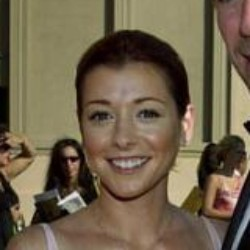

In [ ]:
from IPython.display import Image
Image('lfw/Alyson_Hannigan/Alyson_Hannigan_0001.jpg')

Более сложный вариант - архив в формате `tar`, сжатый архиватором `gzip`. Такие файлы имеют расширение `.tar.gz` (или `.tgz`). В Linux такой формат архивов более популярен, чем `zip`. Именно в таком виде распространяются предварительно обученные модели TensorFlow. 

Давайте загрузим модель TensorFlow для обнаружения объектов на изображениях и распакуем её. Загружаем модель с помощью `wget`:

In [ ]:
!wget http://download.tensorflow.org/models/object_detection/faster_rcnn_inception_resnet_v2_atrous_coco_2018_01_28.tar.gz

--2020-11-18 10:55:12--  http://download.tensorflow.org/models/object_detection/faster_rcnn_inception_resnet_v2_atrous_coco_2018_01_28.tar.gz
Resolving download.tensorflow.org (download.tensorflow.org)... 172.217.203.128, 2607:f8b0:400c:c15::80
Connecting to download.tensorflow.org (download.tensorflow.org)|172.217.203.128|:80... connected.
HTTP request sent, awaiting response... 200 OK
Length: 672221478 (641M) [application/x-tar]
Saving to: ‘faster_rcnn_inception_resnet_v2_atrous_coco_2018_01_28.tar.gz’

faster_rcnn_incepti 100%[===================>] 641.08M   168MB/s    in 4.0s    

2020-11-18 10:55:16 (162 MB/s) - ‘faster_rcnn_inception_resnet_v2_atrous_coco_2018_01_28.tar.gz’ saved [672221478/672221478]



Распаковываем архив:

*Распаковка архива
Действие «`распаковка`» задается с помощью ключа `-x`. И тут снова потребуется ключ `-f` для указания имени файла архива. Также добавим ключ` -v` для визуального отображения хода процесса.*



```
Чтобы распаковать tar.gz используйте опцию xvfz
```



In [ ]:
!tar xvfz faster_rcnn_inception_resnet_v2_atrous_coco_2018_01_28.tar.gz

faster_rcnn_inception_resnet_v2_atrous_coco_2018_01_28/
faster_rcnn_inception_resnet_v2_atrous_coco_2018_01_28/model.ckpt.index
faster_rcnn_inception_resnet_v2_atrous_coco_2018_01_28/checkpoint
faster_rcnn_inception_resnet_v2_atrous_coco_2018_01_28/pipeline.config
faster_rcnn_inception_resnet_v2_atrous_coco_2018_01_28/model.ckpt.data-00000-of-00001
faster_rcnn_inception_resnet_v2_atrous_coco_2018_01_28/model.ckpt.meta
faster_rcnn_inception_resnet_v2_atrous_coco_2018_01_28/saved_model/
faster_rcnn_inception_resnet_v2_atrous_coco_2018_01_28/saved_model/saved_model.pb
faster_rcnn_inception_resnet_v2_atrous_coco_2018_01_28/saved_model/variables/
faster_rcnn_inception_resnet_v2_atrous_coco_2018_01_28/frozen_inference_graph.pb


Проверяем распакованное содержимое архива в каталоге `faster_rcnn_inception_resnet_v2_atrous_coco_2018_01_28`:

In [ ]:
!ls faster_rcnn_inception_resnet_v2_atrous_coco_2018_01_28

checkpoint			model.ckpt.index  saved_model
frozen_inference_graph.pb	model.ckpt.meta
model.ckpt.data-00000-of-00001	pipeline.config


<a id="ai-016-section-06"></a>
## 06 · Разделить Python-пакеты и APT

pip устанавливает mxnet, apt-get — системную библиотеку; отдельный вызов help помогает понять команды APT до изменений среды.

_Далее — исходные ячейки учебного материала._

## Установка пакетов

На colaboratory уже установлено много полезных пакетов Python для машинного обучения и других задач. Но если вам понадобился какой-то новый пакет, то его можно достаточно просто установить с помощью команды `pip`. Например, установим библиотеку [`mxnet`](https://mxnet.apache.org):

In [ ]:
!pip install mxnet

     |████████████████████████████████| 55.0MB 59kB/s 
  Found existing installation: graphviz 0.10.1
    Uninstalling graphviz-0.10.1:
      Successfully uninstalled graphviz-0.10.1


Также иногда может понадобиться установка пакетов операционной системы. Например, библиотеку для работы с архивами в разных форматах [libarchive](https://www.libarchive.org/). Системные пакеты устанавливаются командой `apt-get`:

Apt-Get
 `Команда apt-get` - это мощный консольный инструмент, который работает с Улучшенным инструментарием пакетов (APT) Ubuntu, выполняющий такие функции, как установка новых программных пакетов, обновление имеющихся пакетов, обновления индекса списка пакетов и даже обновление все системы Ubuntu.

In [ ]:
!apt-get install libarchive-dev -y

Reading package lists... Done
Building dependency tree       
Reading state information... Done
The following NEW packages will be installed:
  libarchive-dev
0 upgraded, 1 newly installed, 0 to remove and 14 not upgraded.
Need to get 470 kB of archives.
After this operation, 1,623 kB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu bionic-updates/main amd64 libarchive-dev amd64 3.2.2-3.1ubuntu0.6 [470 kB]
Fetched 470 kB in 1s (685 kB/s)
Selecting previously unselected package libarchive-dev:amd64.
(Reading database ... 144793 files and directories currently installed.)
Preparing to unpack .../libarchive-dev_3.2.2-3.1ubuntu0.6_amd64.deb ...
Unpacking libarchive-dev:amd64 (3.2.2-3.1ubuntu0.6) ...
Setting up libarchive-dev:amd64 (3.2.2-3.1ubuntu0.6) ...
Processing triggers for man-db (2.8.3-2ubuntu0.1) ...


In [ ]:
!apt-get  help

apt 1.6.12ubuntu0.1 (amd64)
Usage: apt-get [options] command
       apt-get [options] install|remove pkg1 [pkg2 ...]
       apt-get [options] source pkg1 [pkg2 ...]

apt-get is a command line interface for retrieval of packages
and information about them from authenticated sources and
for installation, upgrade and removal of packages together
with their dependencies.

Most used commands:
  update - Retrieve new lists of packages
  upgrade - Perform an upgrade
  install - Install new packages (pkg is libc6 not libc6.deb)
  remove - Remove packages
  purge - Remove packages and config files
  autoremove - Remove automatically all unused packages
  dist-upgrade - Distribution upgrade, see apt-get(8)
  dselect-upgrade - Follow dselect selections
  build-dep - Configure build-dependencies for source packages
  clean - Erase downloaded archive files
  autoclean - Erase old downloaded archive files
  check - Verify that there are no broken dependencies
  source - Download source archives
  do

<a id="ai-016-section-07"></a>
## 07 · Получить исходники через Git

clone создаёт каталог models. Просмотр README помогает узнать назначение репозитория, но не выполняет настройку всех моделей.

_Далее — исходные ячейки учебного материала._

## Работа с Git

В Colaboratory можно использовать обычные команды `Git`. Например, склонируем репозиторий с моделями `TensorFlow`:

In [ ]:
!git clone https://github.com/tensorflow/models.git

Cloning into 'models'...
remote: Enumerating objects: 2, done.
remote: Counting objects: 100% (2/2), done.
remote: Compressing objects: 100% (2/2), done.
remote: Total 47439 (delta 0), reused 2 (delta 0), pack-reused 47437
Receiving objects: 100% (47439/47439), 551.78 MiB | 38.99 MiB/s, done.
Resolving deltas: 100% (32661/32661), done.


Проверяем

In [ ]:
!ls models

AUTHORS     community	     ISSUES.md	official  README.md
CODEOWNERS  CONTRIBUTING.md  LICENSE	orbit	  research


In [ ]:
!cat models/README.md

![Logo](https://storage.googleapis.com/model_garden_artifacts/TF_Model_Garden.png)

# Welcome to the Model Garden for TensorFlow

The TensorFlow Model Garden is a repository with a number of different implementations of state-of-the-art (SOTA) models and modeling solutions for TensorFlow users. We aim to demonstrate the best practices for modeling so that TensorFlow users
can take full advantage of TensorFlow for their research and product development.

| Directory | Description |
|-----------|-------------|
| [official](official) | • A collection of example implementations for SOTA models using the latest TensorFlow 2's high-level APIs<br />• Officially maintained, supported, and kept up to date with the latest TensorFlow 2 APIs by TensorFlow<br />• Reasonably optimized for fast performance while still being easy to read |
| [research](research) | • A collection of research model implementations in TensorFlow 1 or 2 by researchers<br />• Maintained and supported by researchers |
| [co

<a id="ai-016-section-08"></a>
## 08 · Сверить среду и дальнейший маршрут

Диагностика CPU/RAM/GPU завершает практикум. Ссылка на отдельный Drive-ноутбук — дополнительный материал, доступ к которому не подтверждён этим файлом.

_Далее — исходные ячейки учебного материала._

## Узнать какой Linux используется в Colaboratory?



In [ ]:

!lsb_release -a

No LSB modules are available.
Distributor ID:	Ubuntu
Description:	Ubuntu 18.04.5 LTS
Release:	18.04
Codename:	bionic


### Узнать сколько процесоров и памяти?

**Процессоры**

In [ ]:
!cat /proc/cpuinfo

processor	: 0
vendor_id	: GenuineIntel
cpu family	: 6
model		: 63
model name	: Intel(R) Xeon(R) CPU @ 2.30GHz
stepping	: 0
microcode	: 0x1
cpu MHz		: 2300.000
cache size	: 46080 KB
physical id	: 0
siblings	: 2
core id		: 0
cpu cores	: 1
apicid		: 0
initial apicid	: 0
fpu		: yes
fpu_exception	: yes
cpuid level	: 13
wp		: yes
flags		: fpu vme de pse tsc msr pae mce cx8 apic sep mtrr pge mca cmov pat pse36 clflush mmx fxsr sse sse2 ss ht syscall nx pdpe1gb rdtscp lm constant_tsc rep_good nopl xtopology nonstop_tsc cpuid tsc_known_freq pni pclmulqdq ssse3 fma cx16 pcid sse4_1 sse4_2 x2apic movbe popcnt aes xsave avx f16c rdrand hypervisor lahf_lm abm invpcid_single ssbd ibrs ibpb stibp fsgsbase tsc_adjust bmi1 avx2 smep bmi2 erms invpcid xsaveopt arat md_clear arch_capabilities
bugs		: cpu_meltdown spectre_v1 spectre_v2 spec_store_bypass l1tf mds swapgs
bogomips	: 4600.00
clflush size	: 64
cache_alignment	: 64
address sizes	: 46 bits physical, 48 bits virtual
power management:

processor	:

Количество процессоров 2, но это означает не два процессора, а два ядра. Производитель процессоров Intel, тактовая частота 2,3 ГГц.

Если есть желание, можете подробнее разобрать информацию из `cpuinfo`, можно найти много интересного. Рекомендую начать с раздела `bugs`.



**Память**

In [ ]:
!free -h

              total        used        free      shared  buff/cache   available
Mem:            12G        571M        3.7G        960K        8.4G         11G
Swap:            0B          0B          0B


Всего памяти 12 ГБ, из них свободно 11ГБ.






## Какой GPU используется?

Если вы подключили GPU в разделе Runtime -> Change Runtime Type -> Hardware accelerator, то модель можно посмотреть следующей командой: 

In [ ]:
!cat /proc/driver/nvidia/gpus/0000:00:04.0/information

Model: 		 Tesla P100-PCIE-16GB
IRQ:   		 35
GPU UUID: 	 GPU-a9d5a6d8-f298-555e-88cf-cf68841a4d8f
Video BIOS: 	 86.00.4d.00.01
Bus Type: 	 PCI
DMA Size: 	 47 bits
DMA Mask: 	 0x7fffffffffff
Bus Location: 	 0000:00:04.0
Device Minor: 	 0
Blacklisted:	 No


In [ ]:
!ls /proc/driver/nvidia/gpus/

0000:00:04.0


## Под каким пользователем Linux выполняются команды в Colaboratory?

In [ ]:
!whoami

root


Имя пользователя - `root`, суперпользователь. Домашний каталог пользователя - `/root`

# [Доп. нотбук Ипорт и экспорт данных через Google Colab + Созранение колбека НС](https://colab.research.google.com/drive/12Ne9qy_wg_aleyzFW62bP2PQeXIAWq-S?usp=sharing)


<a id="ai-016-practice"></a>
## Проверьте понимание

1. Объясните разницу wc -l и wc -c на одном README.
2. Проверьте фактическое имя taxi+_zone_lookup.csv после wget.
3. Исправьте в конспекте описание unrar: e извлекает без путей, x сохраняет полный путь.

### Один самостоятельный эксперимент

Для двух локальных учебных файлов составьте мини-таблицу: путь, первые строки, число строк и байт; отдельно запишите правильный способ распаковки каждого формата.

**Критерий успеха:** Значения получены командами, единицы подписаны; ошибочные описания RAR не повторены как инструкция.

<a id="ai-016-provenance"></a>
## Источники и ограничения

[Исходный ноутбук и его авторские материалы](https://github.com/safal207/students/blob/d848e04c8f8d6e3e8e42ce15fbd98c00612e0e17/Linux/%D0%A0%D0%B0%D0%B1%D0%BE%D1%82%D0%B0_%D1%81_Linux_%D0%BA%D0%BE%D0%BC%D0%B0%D0%BD%D0%B4%D0%B0%D0%BC%D0%B8_%D0%B2_Colab.ipynb) · репозиторий `safal207/students`.

Исходные подписи, ссылки, авторство, код, изображения и аудио сохранены. Длинные текстовые выводы могут быть сокращены с указанием источника. Архивные результаты не пересчитывались.

### Перед новым запуском

- Текстовые пояснения unrar e/x в ячейке 49 перепутаны; сами RAR-команды здесь не выполняются.
- Текст обещает 15 строк, а команда head задаёт 18; ориентируйтесь на фактический аргумент.
- Внешние архивы и дополнительная Drive-ссылка не проверены; учебный LFW-путь зависит от их содержимого.
- Установки меняют Linux-среду; текущие ресурсы и GPU-адрес нельзя выводить из сохранённых старых комментариев.

**Иллюстрации:** обложка направления AI PATH; карта урока подготовлена по содержимому исходных ячеек.